# # Tugas — Deployment Model Pilihan Sendiri: Klasifikasi Digit Tulisan Tangan
#
# Jobsheet **JS15: Pipeline Machine Learning and Deployment** — JTI Polinema 2025/2026.
#
# Tugas meminta menerapkan pipeline deployment yang sama (model `.h5` + scaler `.pkl`
# + `app.py` + `requirements.txt` + `Dockerfile` + Docker Space) pada **model project
# sendiri**.
#
# Model yang dipakai di sini: **klasifikasi digit 0–9** dari dataset *digits*
# scikit-learn (1.797 citra 8×8, setara MNIST versi kecil dan **tersedia offline**).
# Alurnya identik dengan Day/Night — hanya beda data, dimensi fitur, dan head output:
#
# | Aspek | Praktikum (Day/Night) | Tugas (Digit 0–9) |
# |---|---|---|
# | Data | 400 foto 256×256 (day/night) | 1.797 citra 8×8 (digits sklearn) |
# | Fitur | HOG 34.596 dimensi | piksel mentah 64 dimensi (8×8) |
# | Scaler | `StandardScaler` | `StandardScaler` |
# | Output layer | `Dense(1, sigmoid)` + `binary_crossentropy` | `Dense(10, softmax)` + `sparse_categorical_crossentropy` |
# | Label | 1 = day, 0 = night | 0–9 |
# | Artefak | `day_night_model.h5`, `scaler.pkl` | `digit_model.h5`, `digit_scaler.pkl` |
# | Endpoint | `/`, `/predict` (label siang/malam) | `/`, `/predict` (digit + confidence) |
#
# **Deviasi:** artefak model dari jobsheet sebelumnya tidak tersimpan di repo
# (`*.h5` tidak ada), jadi model dilatih ulang di sini dari dataset offline yang
# ringan dan cepat — sesuai instruksi "sederhana dan cepat lebih baik".
# Push ke Hugging Face tetap tidak dilakukan (butuh token).

In [1]:
# Shim agar path konsisten saat notebook dieksekusi dari direktori mana pun.
import os
__file__ = os.path.abspath("tugas_deployment_digit_classifier.ipynb")

# ## Langkah 1: Siapkan Data & Latih Model
#
# Sama seperti Praktikum 1: load → preprocessing → `StandardScaler` →
# split validasi 20% → Dense → simpan artefak.

In [2]:
from pathlib import Path
import importlib
import io
import json
import pickle
import random
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

BASE = Path(__file__).resolve().parent          # .../tugas
ROOT = BASE.parent                              # .../js15-...
OUT = BASE / "output"
DEPLOY = BASE / "deploy"
OUT.mkdir(exist_ok=True)
DEPLOY.mkdir(exist_ok=True)
print("Folder artefak:", DEPLOY)

Folder artefak: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\tugas\deploy


In [3]:
digits = load_digits()
print("Jumlah citra :", digits.images.shape)
print("Ukuran citra :", digits.images[0].shape, "| rentang nilai piksel:", digits.images.min(), "-", digits.images.max())
print("Jumlah kelas :", len(digits.target_names), "->", digits.target_names)

# Preprocessing: 8x8 piksel 0..16 -> 0..1, lalu flatten jadi 64 fitur
X_all = (digits.images.reshape(len(digits.images), -1) / 16.0).astype("float32")
y_all = digits.target.astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all
)

scaler = StandardScaler()
X_train_full_s = scaler.fit_transform(X_train_full)
X_test_s = scaler.transform(X_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full_s, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full
)

print("\nX_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test_s.shape)

Jumlah citra : (1797, 8, 8)
Ukuran citra : (8, 8) | rentang nilai piksel: 0.0 - 16.0
Jumlah kelas : 10 -> [0 1 2 3 4 5 6 7 8 9]

X_train: (1149, 64) | X_val: (288, 64) | X_test: (360, 64)


In [4]:
model = models.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(X_train, y_train, epochs=20, batch_size=32,
                    validation_data=(X_val, y_val), verbose=2)

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 128)               8320      


 dense_1 (Dense)             (None, 64)                8256      


 dense_2 (Dense)             (None, 10)                650       


... (40 outputs left out)

Epoch 19/20


36/36 - 0s - loss: 0.0051 - accuracy: 1.0000 - val_loss: 0.0551 - val_accuracy: 0.9792 - 225ms/epoch - 6ms/step


Epoch 20/20


36/36 - 0s - loss: 0.0045 - accuracy: 1.0000 - val_loss: 0.0544 - val_accuracy: 0.9792 - 215ms/epoch - 6ms/step


# ## Evaluasi pada Data Test

In [5]:
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)
y_pred = model.predict(X_test_s, verbose=0).argmax(axis=1)
print("Akurasi Test:", round(float(test_acc), 6), "| Loss Test:", round(float(test_loss), 6))
print()
print(classification_report(y_test, y_pred))

Akurasi Test: 0.980556 | Loss Test: 0.11979

              precision    recall  f1-score   support

           0       1.00      0.94      0.97        36
           1       0.95      0.97      0.96        36
           2       0.97      1.00      0.99        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.97      0.94      0.96        35
           9       0.97      0.97      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



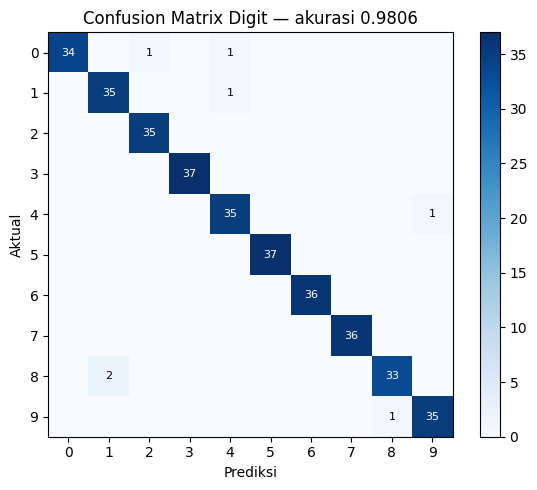

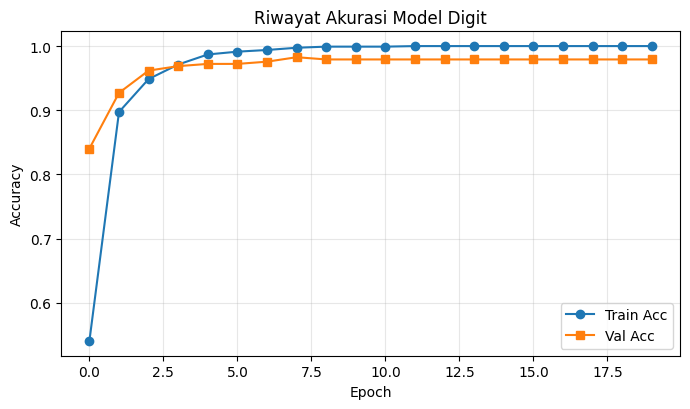

In [6]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual")
ax.set_title(f"Confusion Matrix Digit — akurasi {test_acc:.4f}")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix_digit.png", dpi=110)
plt.show()

plt.figure(figsize=(7, 4.2))
plt.plot(history.history["accuracy"], marker="o", label="Train Acc")
plt.plot(history.history["val_accuracy"], marker="s", label="Val Acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.grid(alpha=0.3); plt.legend()
plt.title("Riwayat Akurasi Model Digit")
plt.tight_layout()
plt.savefig(OUT / "training_history_digit.png", dpi=110)
plt.show()

# ## Langkah 2: Simpan Artefak (`.h5` + `.pkl`) dan Verifikasi Load Ulang

In [7]:
MODEL_PATH = DEPLOY / "digit_model.h5"
SCALER_PATH = DEPLOY / "digit_scaler.pkl"

model.save(MODEL_PATH)
with open(SCALER_PATH, "wb") as f:
    pickle.dump(scaler, f)
print("✅ Model  :", MODEL_PATH, f"({MODEL_PATH.stat().st_size/1024:.1f} KB)")
print("✅ Scaler :", SCALER_PATH, f"({SCALER_PATH.stat().st_size/1024:.1f} KB)")

reload_model = tf.keras.models.load_model(MODEL_PATH)
with open(SCALER_PATH, "rb") as f:
    reload_scaler = pickle.load(f)

uji = 7
prob = reload_model.predict(reload_scaler.transform(X_test[[uji]]), verbose=0)[0]
print(f"\nLoad ulang OK. Citra test #{uji}: label asli={y_test[uji]}, prediksi={prob.argmax()} "
      f"(confidence {prob.max():.4f})")
assert int(prob.argmax()) == int(y_pred[uji])

C:\code\pemmes26\.venv\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


✅ Model  : C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\tugas\deploy\digit_model.h5 (234.3 KB)
✅ Scaler : C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\tugas\deploy\digit_scaler.pkl (1.9 KB)



Load ulang OK. Citra test #7: label asli=2, prediksi=2 (confidence 0.9999)


# ## Langkah 3: `app.py` untuk Model Digit
#
# Beda dari app Day/Night hanya pada preprocessing dan output: citra di-*decode*,
# dijadikan grayscale, **resize ke 8×8** (ukuran yang dipakai saat training),
# dinormalisasi `/255`, lalu di-`scaler.transform`. Output `softmax` 10 kelas →
# diambil `argmax` sebagai digit dan nilai maksimum sebagai confidence.

In [8]:
APP_PY = '''import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string

app = Flask(__name__)

MODEL_PATH = "digit_model.h5"
SCALER_PATH = "digit_scaler.pkl"

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(SCALER_PATH, "rb") as f:
        scaler = pickle.load(f)
    print("✅ System Loaded Successfully")
except Exception as e:
    print(f"❌ Error loading system: {e}")


def preprocess_image(image_bytes):
    # Decode gambar -> grayscale -> 8x8 (sama dengan ukuran training) -> 0..1
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError("File bukan gambar yang valid")
    img = cv2.resize(img, (8, 8), interpolation=cv2.INTER_AREA)
    feat = (img.astype("float32") / 255.0).reshape(1, -1)
    return scaler.transform(feat)


@app.route("/", methods=["GET"])
def home():
    return render_template_string("""
    <div style="text-align:center; padding:50px;">
        <h1>Digit Classifier (0-9)</h1>
        <p>Unggah citra digit tulisan tangan (latar gelap, digit terang).</p>
        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" required><br><br>
            <button type="submit">Prediksi</button>
        </form>
    </div>
    """)


@app.route("/predict", methods=["POST"])
def predict():
    try:
        file = request.files["file"]
        data = preprocess_image(file.read())
        prob = model.predict(data, verbose=0)[0]
        digit = int(np.argmax(prob))
        return (f"<h2 style='text-align:center'>Hasil: {digit} "
                f"(confidence {prob[digit]*100:.2f}%)</h2>"
                f"<center><a href='/'>Kembali</a></center>")
    except Exception as e:
        return f"Error: {e}"


if __name__ == "__main__":
    # Port 7860 wajib untuk Hugging Face Spaces
    app.run(host="0.0.0.0", port=7860)
'''

REQUIREMENTS = """flask
tensorflow-cpu
numpy
scikit-learn
opencv-python-headless
gunicorn
"""

DOCKERFILE = """# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \\
    libgl1 \\
    libglib2.0-0 \\
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]
"""

(DEPLOY / "app.py").write_text(APP_PY, encoding="utf-8")
(DEPLOY / "requirements.txt").write_text(REQUIREMENTS, encoding="utf-8")
(DEPLOY / "Dockerfile").write_text(DOCKERFILE, encoding="utf-8")
for p in ("app.py", "requirements.txt", "Dockerfile"):
    print(f"✅ {p:18s}", (DEPLOY / p).stat().st_size, "byte")
print("\nIsi folder deploy:", sorted(x.name for x in DEPLOY.iterdir()))

✅ app.py             2035 byte
✅ requirements.txt   78 byte
✅ Dockerfile         671 byte

Isi folder deploy: ['Dockerfile', 'app.py', 'digit_model.h5', 'digit_scaler.pkl', 'requirements.txt']


# ## Langkah 4: Uji `app.py` dengan `flask.test_client()`
#
# Gambar uji dibuat dari data test (`output/samples/digit_<n>_label_<y>.png`, dua
# resolusi: 8×8 asli dan 64×64 hasil upscale) supaya alur upload → decode → resize →
# scaler → model.predict benar-benar teruji.

In [9]:
SAMPEL = OUT / "samples"
SAMPEL.mkdir(exist_ok=True)

files = []
for idx in range(40):                      # 40 citra test: 4 per kelas
    lbl = int(y_test[idx])
    img8 = (X_test[idx].reshape(8, 8) * 255).astype("uint8")   # balik ke 0..255
    p8 = SAMPEL / f"digit_{idx:02d}_label_{lbl}_8x8.png"
    cv2.imwrite(str(p8), img8)
    files.append((p8, lbl))
    if idx < 10:                            # 10 pertama juga dibuat versi 64x64
        p64 = SAMPEL / f"digit_{idx:02d}_label_{lbl}_64x64.png"
        cv2.imwrite(str(p64), cv2.resize(img8, (64, 64), interpolation=cv2.INTER_NEAREST))
        files.append((p64, lbl))

print(f"{len(files)} file uji dibuat di {SAMPEL}")

sys.path.insert(0, str(DEPLOY))
os.chdir(DEPLOY)
sys.modules.pop("app", None)
app_module = importlib.import_module("app")
client = app_module.app.test_client()

resp = client.get("/")
print("GET  /        ->", resp.status_code, "| form tampil:", "Digit Classifier" in resp.get_data(as_text=True))
assert resp.status_code == 200

50 file uji dibuat di C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\tugas\output\samples


✅ System Loaded Successfully
GET  /        -> 200 | form tampil: True


# ### Prediksi 40+ gambar uji lewat endpoint `/predict`

In [10]:
rows = []
for path, lbl in files:
    with open(path, "rb") as f:
        resp = client.post("/predict",
                           data={"file": (io.BytesIO(f.read()), path.name)},
                           content_type="multipart/form-data")
    body = resp.get_data(as_text=True)
    if "Hasil: " in body:
        hasil = int(body.split("Hasil: ")[1].split(" ")[0])
        conf = float(body.split("confidence ")[1].split("%")[0])
    else:
        hasil, conf = -1, 0.0
    rows.append({"file": path.name, "label_asli": lbl, "prediksi": hasil,
                 "confidence_%": round(conf, 2), "benar": hasil == lbl})

df = pd.DataFrame(rows)
print(df.head(15).to_string(index=False))
print("...")
akurasi = accuracy_score(df["label_asli"], df["prediksi"])
print(f"\nAkurasi endpoint pada {len(df)} gambar uji: {akurasi:.2%} "
      f"({int(df['benar'].sum())}/{len(df)})")
print("Per resolusi:")
print(df.assign(resolusi=df["file"].str.extract(r"(8x8|64x64)")[0])
        .groupby("resolusi")["benar"].agg(["mean", "count"]).to_string())

df.to_csv(OUT / "prediksi_tugas.csv", index=False)
print("\n✅ Hasil disimpan:", OUT / "prediksi_tugas.csv")

                      file  label_asli  prediksi  confidence_%  benar
  digit_00_label_5_8x8.png           5         5         99.30   True
digit_00_label_5_64x64.png           5         5         99.30   True
  digit_01_label_2_8x8.png           2         2         99.99   True
digit_01_label_2_64x64.png           2         2         99.99   True
  digit_02_label_8_8x8.png           8         8         92.10   True
digit_02_label_8_64x64.png           8         8         92.10   True
  digit_03_label_1_8x8.png           1         1         53.97   True
digit_03_label_1_64x64.png           1         1         53.97   True
  digit_04_label_7_8x8.png           7         7         99.95   True
digit_04_label_7_64x64.png           7         7         99.95   True
  digit_05_label_2_8x8.png           2         2         98.93   True
digit_05_label_2_64x64.png           2         2         98.93   True
  digit_06_label_6_8x8.png           6         6         99.99   True
digit_06_label_6_64x

# ## Langkah 5: Validasi Dockerfile + Status Docker
#
# Sama seperti Praktikum 2: validasi statis karena build image (base TensorFlow ±1 GB)
# tidak dijalankan dan Docker daemon tidak aktif.

In [11]:
df_text = (DEPLOY / "Dockerfile").read_text(encoding="utf-8")
wajib = ["FROM python:3.9-slim", "libgl1", "libglib2.0-0", "useradd -m -u 1000 user",
         "USER user", "WORKDIR /app", "pip install", "COPY --chown=user . /app",
         "EXPOSE 7860", 'CMD ["python", "app.py"]']
for token in wajib:
    print(f"[{'OK  ' if token in df_text else 'MISS'}] {token}")
assert all(t in df_text for t in wajib)

info = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"],
                      capture_output=True, text=True)
print("\nDocker daemon aktif:", info.returncode == 0)

[OK  ] FROM python:3.9-slim
[OK  ] libgl1
[OK  ] libglib2.0-0
[OK  ] useradd -m -u 1000 user
[OK  ] USER user
[OK  ] WORKDIR /app
[OK  ] pip install
[OK  ] COPY --chown=user . /app
[OK  ] EXPOSE 7860
[OK  ] CMD ["python", "app.py"]



Docker daemon aktif: False


# ## Langkah 6: Deploy ke Hugging Face Space (manual — butuh token mahasiswa)
#
# ```bash
# # 1. Buat Space baru: SDK = Docker, Template kosong, Visibility Public
# # 2. Settings > Access Tokens > Create new token (permission Write)
# git clone https://huggingface.co/spaces/USERNAME_ANDA/digit-classifier
# cd digit-classifier
# cp ../js15-pipeline-machine-learning-and-deployment/tugas/deploy/{app.py,Dockerfile,requirements.txt,digit_model.h5,digit_scaler.pkl} .
# git add .
# git commit -m "Deploy klasifikasi digit ke HF"
# git push      # username: USERNAME_ANDA | password: ACCESS TOKEN (bukan password akun)
# ```
#
# **Jangan** menuliskan token ke dalam file yang di-commit, notebook, atau chat.
# Setelah status Space `Running` (hijau), unggah gambar digit lewat tab **App**.
#
# Deviasi: langkah ini tidak dieksekusi di notebook (butuh kredensial pribadi).
# Bukti yang bisa diverifikasi adalah uji lokal `/` dan `/predict` di atas.

# ## Ringkasan

In [12]:
ringkasan = {
    "dataset": "sklearn digits 8x8 (1797 citra)",
    "fitur": 64,
    "arsitektur": "Dense128-relu -> Dense64-relu -> Dense10-softmax",
    "epoch": 20,
    "akurasi_test": round(float(test_acc), 4),
    "akurasi_endpoint_flask": round(float(akurasi), 4),
    "jumlah_gambar_uji_endpoint": len(df),
    "docker_daemon_aktif": info.returncode == 0,
    "seed": SEED,
}
(OUT / "ringkasan_tugas.json").write_text(json.dumps(ringkasan, indent=2), encoding="utf-8")
print(json.dumps(ringkasan, indent=2))

{
  "dataset": "sklearn digits 8x8 (1797 citra)",
  "fitur": 64,
  "arsitektur": "Dense128-relu -> Dense64-relu -> Dense10-softmax",
  "epoch": 20,
  "akurasi_test": 0.9806,
  "akurasi_endpoint_flask": 1.0,
  "jumlah_gambar_uji_endpoint": 50,
  "docker_daemon_aktif": false,
  "seed": 42
}
